# Build retrieval yourself, then measure it

**Course** MLAIDP · **Module 3 — Vector Databases and Retrieval Augmentation**
· **When:** after slide 45 (*Hybrid retrieval strategy implementation cont.*), before slide 46 (*Enterprise knowledge
assistant development (1 of 3)*)
· **Kernel** MLAIDP (Python 3.12) · your AWS credentials (`AWS_PROFILE` or the default chain), us-east-1
· **Runtime** about 1.5 minutes of cell time (one minute of it is the rerank quota) · **Cost per run** about $0.05
(almost all of it reranking)

**Scenario:** the **AnyCompany Insurance** support desk answers questions about home and motor policies and the
claims process. Its assistant is only as good as the chunks it retrieves — so build the retriever and measure it.

**What you'll learn**
- Write three **chunkers** (fixed-size, structure-aware with a contextual header, semantic breakpoints on embedding
  similarity) and see where each one cuts a fact in half.
- Store **Titan Text Embeddings V2** vectors in **Amazon S3 Vectors** through the API: vector bucket, index,
  `put_vectors` with filterable metadata, `query_vectors` with a **metadata filter** — and what an unfiltered query
  pulls in from the wrong product.
- Build **hybrid retrieval** in code: BM25 written in Python + vector search, fused with **reciprocal rank fusion**,
  then **Cohere Rerank 3.5** through `bedrock-agent-runtime.rerank`.
- Score every variant on a 22-question golden set with **Hit@k, MRR and nDCG@5**, a **paired bootstrap** interval on
  the improvement, and latency and $ per 1,000 queries per layer.

> **Resources:** S3 vector bucket `mlaidp2-m03-<run id>` with three indexes, and S3 bucket
> `mlaidp2-m03-docs-<run id>` holding the three documents with `.metadata.json` sidecars (used by the console
> part). Both are created in §0 in a few seconds; the cleanup section deletes them.

## §0 Setup

In [1]:
import sys, json, math, re, threading, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
sys.path.insert(0, "../common")
import mlaidp as m
from botocore.exceptions import ClientError

RID = m.setup_banner("M03")
bedrock, agent_rt = m.client("bedrock-runtime"), m.client("bedrock-agent-runtime")
s3vectors, s3 = m.client("s3vectors"), m.client("s3")

VECTOR_BUCKET = f"mlaidp2-m03-{RID}"           # S3 Vectors: one bucket, one index per chunker
DOCS_BUCKET = f"mlaidp2-m03-docs-{RID}"        # plain S3: the source documents (read by the console's Knowledge Base)
DIMS, K, POOL = 1024, 5, 20                    # vector size; results the model sees; candidates fed to fusion/rerank

# Prices (AWS Price List API, us-east-1, read 2026-10-21): Titan V2 input tokens, S3 Vectors query request, rerank
USD_TITAN_PER_1K_TOKENS = m.PRICES[m.TITAN_EMBED_V2]["in"]
USD_S3V_PER_QUERY = 2.5 / 1_000_000            # + $/GB processed, negligible at this index size
USD_RERANK_PER_QUERY = m.RERANK_USD_PER_QUERY  # Cohere Rerank 3.5: one "query" = up to 100 documents
RERANK_QUOTA_CODE = "L-11512E58"              # "On-demand model inference requests per minute for Cohere Rerank 3.5"

account 1143…  ·  us-east-1  ·  credentials AWS_PROFILE  ·  run id 10220f2e


### §0 Prep — the corpus
Three documents, two products: the home policy wording, the agents' claims manual (both product `home`) and a
motor policy wording (product `motor`) that uses the **same vocabulary** — deductibles, glass, theft, flood — with
different numbers. The documents go to S3 with a `.metadata.json` sidecar each: the format a Bedrock Knowledge Base
reads (Part 2). The notebook itself reads the local copies.

In [2]:
DOCS = [  # (file, product, kind)
    (m.ASSETS / "m03_docs/home_policy_wording_HP-2026.txt", "home", "policy"),
    (m.ASSETS / "m03_docs/claims_handling_manual_agents.txt", "home", "manual"),
    (m.ASSETS / "m03_motor_policy_wording_MP-2026.txt", "motor", "policy"),
]
CORPUS = [{"doc": f.stem, "product": p, "kind": k, "text": f.read_text()} for f, p, k in DOCS]

try:
    s3.head_bucket(Bucket=DOCS_BUCKET)
except ClientError:
    s3.create_bucket(Bucket=DOCS_BUCKET)
    s3.put_bucket_tagging(Bucket=DOCS_BUCKET, Tagging={"TagSet": [{"Key": k, "Value": v} for k, v in m.TAGS.items()]})
for (f, product, kind) in DOCS:
    s3.put_object(Bucket=DOCS_BUCKET, Key=f"docs/{f.name}", Body=f.read_bytes(), ContentType="text/plain")
    s3.put_object(Bucket=DOCS_BUCKET, Key=f"docs/{f.name}.metadata.json",
                  Body=json.dumps({"metadataAttributes": {"product": product, "kind": kind}}).encode())
m.table([[d["doc"], d["product"], d["kind"], len(d["text"])] for d in CORPUS], ["Document", "product", "kind", "chars"],
        caption=f"uploaded to s3://{DOCS_BUCKET}/docs/ with .metadata.json sidecars")

Document,product,kind,chars
home_policy_wording_HP-2026,home,policy,6064
claims_handling_manual_agents,home,manual,2189
m03_motor_policy_wording_MP-2026,motor,policy,3591


## 1 · Three chunkers
The chunk is the unit of retrieval: if a fact is split across two chunks, no ranking trick returns it whole.
- **Fixed-size** — 60 words (≈ 80 tokens) with a 10-word overlap: cheap, predictable, blind to structure.
  The overlap is what saves a fact that straddles a boundary — at the price of duplicated text.
- **Structure-aware** — split at headings and paragraphs, merge short paragraphs, and prefix every chunk with a
  **contextual header** (document › section) so a chunk still says where it came from.

In [3]:
def fixed_chunks(text: str, size: int = 60, overlap: int = 10) -> list[str]:
    words = text.split()
    return [" ".join(words[i:i + size]) for i in range(0, max(1, len(words) - overlap), size - overlap)]

def is_heading(par: str) -> bool:
    return "\n" not in par and len(par) < 60 and not par.endswith((".", ":")) and not par.startswith("-")

def structure_chunks(text: str, min_chars: int = 250, max_chars: int = 900) -> list[str]:
    title, section, out, buf = text.splitlines()[0], "", [], ""
    for par in [p.strip() for p in text.split("\n\n")[1:] if p.strip()]:
        if is_heading(par):                                       # a new section closes the open chunk
            out, buf, section = out + [buf] if buf else out, "", par
            continue
        if buf and len(buf) + len(par) > max_chars:
            out, buf = out + [buf], ""
        buf = f"{buf}\n{par}" if buf else f"[{title} › {section or 'Introduction'}]\n{par}"
        if len(buf) >= min_chars:                                 # big enough: close it
            out, buf = out + [buf], ""
    return out + [buf] if buf else out

print(fixed_chunks(CORPUS[1]["text"])[2], "\n---")
print(structure_chunks(CORPUS[1]["text"])[1])

customer exactly which ones. - R7 - Suspended pending fraud review. Do not discuss the reason with the customer. Say that the claim needs an additional review and that a specialist team will contact them within 10 business days. Never mention fraud. - R9 - Settled. Payment has been released. It reaches the customer's bank within 3 business days. - 
---
[AnyCompany Insurance - Claims Handling Manual for Contact Center Agents › Status codes in the claims system]
Every claim carries one status code. Read the code to the customer in plain words, never as the code itself.


- **Semantic** — split into sentences, embed every sentence, and cut where the similarity between neighbours drops
  into its lowest 20 % (the idea behind Knowledge Bases' *semantic chunking*, here in 15 lines). It costs one
  embedding per sentence at ingestion time.

The embedding call is plain `InvokeModel` on **Titan Text Embeddings V2**: choose the output size (256/512/1,024)
and normalise, so the dot product *is* the cosine similarity.

In [4]:
EMBED_TOKENS = Counter()                                   # input tokens per stage, for the cost line

def embed(text: str, stage: str = "ingest") -> np.ndarray:
    r = bedrock.invoke_model(modelId=m.TITAN_EMBED_V2,
                             body=json.dumps({"inputText": text, "dimensions": DIMS, "normalize": True}))
    body = json.loads(r["body"].read())
    EMBED_TOKENS[stage] += body["inputTextTokenCount"]
    return np.array(body["embedding"], dtype=np.float32)

def embed_many(texts: list[str], stage: str = "ingest") -> np.ndarray:
    with ThreadPoolExecutor(4) as pool:                    # ≤ 4 parallel calls in a shared account
        return np.stack(list(pool.map(lambda t: embed(t, stage), texts)))

def semantic_chunks(text: str, low_pct: float = 20, max_chars: int = 700) -> list[str]:
    sents = [s.strip() for s in re.split(r"(?<=[.:])\s+(?=[A-Z0-9])|\n+", text) if len(s.strip()) > 2]
    v = embed_many(sents, "semantic chunking")
    sim = np.sum(v[:-1] * v[1:], axis=1)                   # cosine of each sentence with the next one
    cut = np.percentile(sim, low_pct)
    out, buf = [], sents[0]
    for s, prev_sim in zip(sents[1:], sim):
        if prev_sim < cut or len(buf) + len(s) > max_chars:
            out, buf = out + [buf], s
        else:
            buf += " " + s
    return out + [buf]

In [5]:
CHUNKERS = {"fixed": fixed_chunks, "structure": structure_chunks, "semantic": semantic_chunks}
CHUNKS = {}                                                # chunker -> list of {key, text, doc, product, kind}
for name, chunker in CHUNKERS.items():
    CHUNKS[name] = [{"key": f"{d['doc'][:12]}-{i:03d}", "text": t,
                     "doc": d["doc"], "product": d["product"], "kind": d["kind"]}
                    for d in CORPUS for i, t in enumerate(chunker(d["text"]))]

norm = lambda t: " ".join(t.split()).lower()
def keeps_together(chunks, *phrases) -> bool:              # is there ONE chunk that holds every phrase?
    return any(all(norm(p) in norm(c["text"]) for p in phrases) for c in chunks)

R7 = ("R7 - Suspended pending fraud review", "Never mention fraud")
TABLE_ROW = ("Cause of damage", "Glass breakage (Section 2.5)")
m.table([{"chunker": n, "chunks": len(cs), "mean chars": int(np.mean([len(c["text"]) for c in cs])),
          "max chars": max(len(c["text"]) for c in cs),
          "R7 + its rule in one chunk": "✓" if keeps_together(cs, *R7) else "✗",
          "table row + header in one chunk": "✓" if keeps_together(cs, *TABLE_ROW) else "✗"}
         for n, cs in CHUNKS.items()])
print(f"embedding tokens so far: {dict(EMBED_TOKENS)}")

chunker,chunks,mean chars,max chars,R7 + its rule in one chunk,table row + header in one chunk
fixed,42,324,390,✓,✓
structure,43,342,828,✓,✓
semantic,37,316,680,✗,✓


embedding tokens so far: {'semantic chunking': 2724}


> **Think about it:** The fixed chunker is the default in many tutorials. Which kinds of documents in *your*
> organisation would it damage most — and how would you notice before a customer does?

<details><summary>More questions</summary>

- The contextual header costs tokens in every chunk. When is it worth it?
- Semantic chunking costs one embedding per sentence at ingestion. When does a re-ingestion make that expensive?
</details>

## 2 · Amazon S3 Vectors through the API
A **vector bucket** holds **vector indexes**; an index fixes the dimension and the distance metric. Metadata is
filterable by default — declare the chunk text **non-filterable** (it is only returned, never filtered on, and the
filterable part of a vector's metadata is capped at 2 KB). One index per chunker, so the comparison is fair.

In [6]:
INDEX_CONFIG = {"dataType": "float32", "dimension": DIMS, "distanceMetric": "cosine",
                "metadataConfiguration": {"nonFilterableMetadataKeys": ["text"]}}
try:
    s3vectors.get_vector_bucket(vectorBucketName=VECTOR_BUCKET)
except ClientError as e:
    if m.error_code(e) != "NotFoundException":
        raise
    s3vectors.create_vector_bucket(vectorBucketName=VECTOR_BUCKET, tags=m.TAGS)
existing = {i["indexName"] for i in s3vectors.list_indexes(vectorBucketName=VECTOR_BUCKET)["indexes"]}
for name in CHUNKS:
    if name not in existing:
        s3vectors.create_index(vectorBucketName=VECTOR_BUCKET, indexName=name, tags=m.TAGS, **INDEX_CONFIG)
idx = s3vectors.get_index(vectorBucketName=VECTOR_BUCKET, indexName="structure")["index"]
SHOW = ("indexName", "dataType", "dimension", "distanceMetric", "metadataConfiguration", "indexMode")
print(json.dumps({k: idx[k] for k in SHOW}, indent=1))

{
 "indexName": "structure",
 "dataType": "float32",
 "dimension": 1024,
 "distanceMetric": "cosine",
 "metadataConfiguration": {
  "nonFilterableMetadataKeys": [
   "text"
  ]
 },
 "indexMode": "ENHANCED"
}


Load the vectors: embed every chunk, `put_vectors` in batches (up to 500 per call) with metadata. **Idempotent by
key**: a re-run overwrites the same keys, and keys that no longer exist in the chunker's output are deleted — the
index never serves a stale chunk.

In [7]:
def load_index(name: str) -> dict:
    chunks, t0 = CHUNKS[name], time.time()
    vectors = embed_many([c["text"] for c in chunks])
    for i in range(0, len(chunks), 100):
        s3vectors.put_vectors(vectorBucketName=VECTOR_BUCKET, indexName=name, vectors=[
            {"key": c["key"], "data": {"float32": v.tolist()},
             "metadata": {"doc": c["doc"], "product": c["product"], "kind": c["kind"], "text": c["text"]}}
            for c, v in zip(chunks[i:i + 100], vectors[i:i + 100])])
    stored = [v["key"] for page in s3vectors.get_paginator("list_vectors").paginate(
        vectorBucketName=VECTOR_BUCKET, indexName=name) for v in page["vectors"]]
    stale = sorted(set(stored) - {c["key"] for c in chunks})
    if stale:
        s3vectors.delete_vectors(vectorBucketName=VECTOR_BUCKET, indexName=name, keys=stale)
    return {"index": name, "vectors": len(chunks), "stale deleted": len(stale), "seconds": round(time.time() - t0, 1)}

m.table([load_index(n) for n in CHUNKS])
ingest_usd = sum(EMBED_TOKENS.values()) / 1000 * USD_TITAN_PER_1K_TOKENS
print(f"embedding tokens: {dict(EMBED_TOKENS)}  ->  ${ingest_usd:.5f} for the whole corpus, three times")

index,vectors,stale deleted,seconds
fixed,42,0,7.700000
structure,43,0,2.700000
semantic,37,0,2.300000


embedding tokens: {'semantic chunking': 2724, 'ingest': 9109}  ->  $0.00024 for the whole corpus, three times


### Query with a metadata filter
The customer's policy is known before the search starts — use it. `query_vectors` takes a filter on the metadata
(`$eq`, `$in`, `$and`, `$gte`, …). Indexes created after 30 September 2026 run in **ENHANCED** mode: the filter is
applied *before* the nearest-neighbour search, so a selective filter still returns `topK` results.

In [8]:
CHUNK_BY_KEY = {name: {c["key"]: c for c in cs} for name, cs in CHUNKS.items()}

def vector_search(index: str, question: str, product: str | None = None, top_k: int = POOL) -> tuple[list[str], dict]:
    t0 = time.perf_counter()
    qv = embed(question, "queries")
    t1 = time.perf_counter()
    kw = {"filter": {"product": {"$eq": product}}} if product else {}
    r = s3vectors.query_vectors(vectorBucketName=VECTOR_BUCKET, indexName=index, topK=top_k,
                                queryVector={"float32": qv.tolist()}, returnDistance=True, **kw)
    ms = {"embed": (t1 - t0) * 1000, "query": (time.perf_counter() - t1) * 1000}
    return [v["key"] for v in r["vectors"]], ms

q = "What is my deductible when a window breaks?"
for product in (None, "home"):
    keys, ms = vector_search("structure", q, product, top_k=3)
    print(f"filter={product!s:5}  embed {ms['embed']:.0f} ms + query {ms['query']:.0f} ms")
    for k in keys:
        c = CHUNK_BY_KEY["structure"][k]
        print(f"   [{c['product']:5}] {norm(c['text'])[:110]}")

filter=None   embed 181 ms + query 198 ms
   [home ] [anycompany insurance - home policy wording hp-2026 › section 4 - deductibles] the deductible is the part of e
   [motor] [anycompany insurance - motor policy wording mp-2026 › section 4 - deductibles] the deductible is the part of 
   [home ] [anycompany insurance - home policy wording hp-2026 › section 2 - what is covered] 2.5 accidental breakage of 


filter=home   embed 155 ms + query 186 ms
   [home ] [anycompany insurance - home policy wording hp-2026 › section 4 - deductibles] the deductible is the part of e
   [home ] [anycompany insurance - home policy wording hp-2026 › section 2 - what is covered] 2.5 accidental breakage of 
   [home ] [anycompany insurance - home policy wording hp-2026 › section 4 - deductibles] if one event causes damage that


> **Think about it:** Without the filter, the motor wording's deductibles compete with the home wording's for "a
> window breaks". What else besides the product would you put in the metadata of a real policy library — and who
> sets it?

<details><summary>More questions</summary>

- The claims manual is internal. Which filter keeps it out of a customer-facing chatbot — and is a filter enough?
- What happens to a filter-on-the-fly design when a policy version is superseded (slide 28)?
</details>

## 3 · A golden set and three metrics
22 questions from support traffic, each with the **phrases that must appear together in one chunk of the right
product**. Grading by phrase (not by chunk id) lets the three chunkers be judged by the same answer key.
A chunk is **relevant** (grade 2) if it holds every phrase, **partial** (grade 1) if it holds some.
- **Hit@k** — is a relevant chunk in the top *k*? · **MRR** — 1 / rank of the first relevant chunk (rewards rank 1).
- **nDCG@5** — graded gains discounted by log₂(rank + 1), divided by the best possible ordering.

In [9]:
GOLDEN = [  # (id, question, product, phrases that must ALL be in one chunk of that product)
    ("Q01", "My claim shows status R7. What does that mean and what do I tell the customer?", "home",
     ["R7 - Suspended pending fraud review", "Never mention fraud"]),
    ("Q02", "Which ticket type do I open when a customer was charged the premium twice?", "home", ["BIL-DUP"]),
    ("Q03", "What does clause 7.3.2 say?", "home", ["7.3.2 Where an item belongs to a pair"]),
    ("Q04", "The status is X2. What should the agent offer?", "home", ["X2 - Declined", "complaints procedure"]),
    ("Q05", "The claim has been waiting for documents for five weeks. What now?", "home", ["R4 for more than 30 days"]),
    ("Q06", "We can't live in the house after the fire. Will you pay for a hotel, and for how long?", "home",
     ["up to 30 nights"]),
    ("Q07", "Water came in from the river next to our house. Am I covered?", "home",
     ["Flood, unless the flood add-on"]),
    ("Q08", "Burglars took my diamond ring. What is the most you will pay for jewellery?", "home",
     ["Jewelry is covered up to 1,500 USD"]),
    ("Q09", "The soaked carpet smells. Can I throw it away before the adjuster comes?", "home",
     ["decline the part of the claim"]),
    ("Q10", "The pipe was rusty and we knew it, and now it burst. Do you pay?", "home", ["lack of maintenance"]),
    ("Q11", "What is my deductible when a window breaks?", "home", ["Glass breakage (Section 2.5)"]),
    ("Q12", "How strong must the wind be to count as a storm?", "home", ["89 km/h"]),
    ("Q13", "When is my house considered empty for insurance purposes?", "home", ["more than 60 consecutive days"]),
    ("Q14", "I lost one earring of a pair. Do you pay for both?", "home", ["one of two matching earrings"]),
    ("Q15", "Can an agent approve 800 USD for drying equipment without asking anyone?", "home",
     ["Anything above 500 USD needs a team leader"]),
    ("Q16", "The caller has a newborn baby and the kitchen is flooded by a burst pipe. "
            "What can we offer straight away?", "home", ["newborn baby", "emergency accommodation"]),
    ("Q17", "How long after we agree the amount do you pay?", "home", ["within 10 business days of agreeing"]),
    ("Q18", "What is the deductible for a theft from my home?", "home", ["Theft (Section 2.4)"]),
    ("Q19", "My car stood in a flooded street. Is it covered and what do I pay myself?", "motor",
     ["Flood and storm (Section 2.4)"]),
    ("Q20", "How many days do I get a courtesy car while mine is repaired?", "motor", ["up to 14 days"]),
    ("Q21", "How soon must I report a car accident?", "motor", ["within 14 days"]),
    ("Q22", "What is the deductible for replacing a cracked windscreen?", "motor",
     ["Windscreen replacement (Section 2.5)"]),
]
print(len(GOLDEN), "questions ·", sum(q[2] == "motor" for q in GOLDEN), "about the motor product")

22 questions · 4 about the motor product


In [10]:
def grade(chunk: dict, q) -> int:
    _, _, product, phrases = q
    if chunk["product"] != product:
        return 0
    found = sum(norm(p) in norm(chunk["text"]) for p in phrases)
    return 2 if found == len(phrases) else 1 if found else 0

def score(grades: list[int], ideal: list[int], k: int = K) -> dict:
    first = next((i for i, g in enumerate(grades) if g == 2), None)
    dcg = lambda gs: sum((2 ** g - 1) / math.log2(i + 2) for i, g in enumerate(gs[:k]))
    return {"hit@1": float(first == 0), f"hit@{k}": float(first is not None and first < k),
            "mrr": 1 / (first + 1) if first is not None else 0.0,
            f"ndcg@{k}": dcg(grades) / best if (best := dcg(sorted(ideal, reverse=True))) else 0.0,
            f"recall@{POOL}": float(first is not None)}           # is it anywhere in the candidate pool?

print(score([0, 2, 1, 0, 0], [2, 1, 0, 0, 0]))                  # relevant at rank 2: MRR 0.5, nDCG below 1

{'hit@1': 0.0, 'hit@5': 1.0, 'mrr': 0.5, 'ndcg@5': 0.6590018048024133, 'recall@20': 1.0}


Before any search: how many of the 22 answers does each chunker keep **whole** in one chunk of the right product?
That is the ceiling for every retriever built on top of it.

In [11]:
def kept_whole(cs: list[dict]) -> list[str]:
    return [q[0] for q in GOLDEN if any(grade(c, q) == 2 for c in cs)]

m.table([{"chunker": n, "answers kept whole": f"{len(kept_whole(cs))} / {len(GOLDEN)}",
          "split or missing": " ".join(q[0] for q in GOLDEN if q[0] not in kept_whole(cs)) or "–"}
         for n, cs in CHUNKS.items()])

chunker,answers kept whole,split or missing
fixed,22 / 22,–
structure,22 / 22,–
semantic,21 / 22,Q01


### Which chunker? (vector search, with and without the product filter)
Same questions, same embedding model, same store — only the chunking differs. Each question costs one embedding
plus one `query_vectors`; 132 searches, four at a time.

In [12]:
def evaluate(index: str, ranked: dict[str, list[str]]) -> list[dict]:
    """Per-question scores for one variant: ranked = {question id: [chunk keys, best first]}."""
    rows = []
    for q in GOLDEN:
        grades = [grade(CHUNK_BY_KEY[index][k], q) for k in ranked[q[0]]]
        rows.append({"q": q[0], **score(grades, [grade(c, q) for c in CHUNKS[index]]),
                     "foreign": sum(CHUNK_BY_KEY[index][k]["product"] != q[2] for k in ranked[q[0]][:K])})
    return rows

def summary(name: str, rows: list[dict], **extra) -> dict:
    out = {"variant": name, **{k: np.mean([r[k] for r in rows]) for k in ("hit@1", f"hit@{K}", "mrr", f"ndcg@{K}")}}
    return {**out, "misses": " ".join(r["q"] for r in rows if not r[f"hit@{K}"]) or "–", **extra}

def search_all(index: str, use_filter: bool) -> dict:
    with ThreadPoolExecutor(4) as pool:
        res = list(pool.map(lambda q: vector_search(index, q[1], q[2] if use_filter else None), GOLDEN))
    return {q[0]: keys for q, (keys, _) in zip(GOLDEN, res)}

CHUNKER_ROWS, PER_Q = [], {}
for index in CHUNKS:
    for use_filter in (False, True):
        PER_Q[(index, use_filter)] = rows = evaluate(index, search_all(index, use_filter))
        CHUNKER_ROWS.append(summary(f"{index} · {'filter product' if use_filter else 'no filter'}", rows,
                                    **{"wrong-product chunks in top 5": sum(r["foreign"] for r in rows)}))
m.table(CHUNKER_ROWS, fmt={c: "{:.2f}" for c in ("hit@1", f"hit@{K}", "mrr", f"ndcg@{K}")})

variant,hit@1,hit@5,mrr,ndcg@5,misses,wrong-product chunks in top 5
fixed · no filter,0.45,0.82,0.64,0.67,Q03 Q07 Q16 Q19,19
fixed · filter product,0.50,0.86,0.67,0.71,Q03 Q07 Q16,0
structure · no filter,0.73,0.86,0.79,0.80,Q03 Q05 Q16,14
structure · filter product,0.73,0.91,0.80,0.82,Q05 Q16,0
semantic · no filter,0.59,0.82,0.69,0.73,Q01 Q03 Q05 Q16,17
semantic · filter product,0.59,0.82,0.70,0.74,Q01 Q03 Q05 Q16,0


Did a chunker miss the status-code question — and if so, why? Look at the top chunk each chunker returns for **Q01**.

In [13]:
q01 = GOLDEN[0]
for index in CHUNKS:
    keys, _ = vector_search(index, q01[1], q01[2], top_k=3)
    top = CHUNK_BY_KEY[index][keys[0]]
    has = [p for p in q01[3] if norm(p) in norm(top["text"])]
    print(f"{index:9} grade {grade(top, q01)}  holds {has or 'neither phrase'}\n          {norm(top['text'])[:230]}…\n")

fixed     grade 0  holds neither phrase
          never as the code itself. - r1 - registered. the claim has been recorded. no adjuster assigned yet. - r2 - adjuster assigned. tell the customer the adjuster will call within 2 business days. - r4 - waiting for documents. photos, r…



structure grade 2  holds ['R7 - Suspended pending fraud review', 'Never mention fraud']
          [anycompany insurance - claims handling manual for contact center agents › status codes in the claims system] - r1 - registered. the claim has been recorded. no adjuster assigned yet. - r2 - adjuster assigned. tell the customer th…



semantic  grade 0  holds neither phrase
          - r1 - registered. the claim has been recorded. no adjuster assigned yet. - r2 - adjuster assigned. tell the customer the adjuster will call within 2 business days. - r4 - waiting for documents. photos, receipts or a police refere…



> **Think about it:** Suppose one chunker wins on this corpus. Would you ship that choice for a corpus of 10,000
> scanned PDFs? What would you have to measure first?

<details><summary>More questions</summary>

- Count the wrong-product chunks: what does that number cost you in tokens — and in wrong answers?
- 22 questions: how many would you need before a 0.05 difference in MRR means something? (Next section.)
</details>

## 4 · Hybrid retrieval and reranking (slides 12, 45)
S3 Vectors is semantic-only. The keyword half is **BM25** — here in 20 lines over the structure-aware chunks. The
tokenizer keeps identifiers like `r7`, `bil-dup` and `7.3.2` whole: those are exactly the tokens embeddings blur.

In [14]:
STOP = set("a an the of to in on and or is are be for my i we you your do does what how when which can will "
           "with it this that at by from as if our me us after".split())
tokenize = lambda t: [w for w in re.findall(r"[a-z0-9]+(?:[.\-][a-z0-9]+)*", t.lower()) if w not in STOP]

class BM25:
    def __init__(self, texts: list[str], k1: float = 1.2, b: float = 0.75):
        self.docs = [tokenize(t) for t in texts]
        self.tf = [Counter(d) for d in self.docs]
        self.avg_len, n = np.mean([len(d) for d in self.docs]), len(self.docs)
        df = Counter(w for d in self.docs for w in set(d))
        self.idf = {w: math.log(1 + (n - c + 0.5) / (c + 0.5)) for w, c in df.items()}   # rare terms weigh more
        self.k1, self.b = k1, b

    def scores(self, query: str) -> np.ndarray:
        out = np.zeros(len(self.docs))
        for w in tokenize(query):
            for i, (tf, d) in enumerate(zip(self.tf, self.docs)):
                if w in tf:                                       # term-frequency saturation + length normalisation
                    norm_len = 1 - self.b + self.b * len(d) / self.avg_len
                    out[i] += self.idf[w] * tf[w] * (self.k1 + 1) / (tf[w] + self.k1 * norm_len)
        return out

INDEX = "structure"
bm25 = BM25([c["text"] for c in CHUNKS[INDEX]])

def keyword_search(question: str, product: str, top_k: int = POOL) -> list[str]:
    s = bm25.scores(question)
    return [CHUNKS[INDEX][i]["key"] for i in np.argsort(-s)
            if s[i] > 0 and CHUNKS[INDEX][i]["product"] == product][:top_k]

print("BM25 for 'clause 7.3.2':", keyword_search("What does clause 7.3.2 say?", "home", 3))

BM25 for 'clause 7.3.2': ['home_policy_-021', 'claims_handl-002']


**Reciprocal rank fusion** ignores the raw scores (BM25 and cosine live on different scales) and adds 1/(60 + rank)
from every list a chunk appears in. **Rerank** is a cross-encoder: it reads the question and each candidate
*together*. Here is the request — it works on any text, not only on a Knowledge Base.

In [15]:
def rrf(*rankings: list[str], k: int = 60, top_k: int = POOL) -> list[str]:
    fused = Counter()
    for ranking in rankings:
        for rank, key in enumerate(ranking):
            fused[key] += 1 / (k + rank + 1)
    return [key for key, _ in fused.most_common(top_k)]

The reranker has its own on-demand quota (requests per minute, Service Quotas). A production client paces itself to
it rather than retrying into `ThrottlingException`s — and the pacing delay is queueing, not service latency.

In [16]:
class RateLimiter:
    """Client-side pacing to the account quota: queue here instead of collecting ThrottlingExceptions."""
    def __init__(self, per_minute: float):
        self.interval, self.next_at, self.lock = 60 / per_minute, 0.0, threading.Lock()
    def wait(self):
        with self.lock:
            now = time.monotonic()
            self.next_at = max(self.next_at, now) + self.interval
            delay = self.next_at - self.interval - now
        time.sleep(max(0.0, delay))

quotas = m.client("service-quotas")
RERANK_RPM = quotas.get_service_quota(ServiceCode="bedrock", QuotaCode=RERANK_QUOTA_CODE)["Quota"]["Value"]
rerank_pacer = RateLimiter(RERANK_RPM * 0.9)                    # keep 10 % headroom for the other users of the account
print(f"Cohere Rerank 3.5 on-demand quota in this account: {RERANK_RPM:.0f} requests per minute")

def rerank(question: str, keys: list[str], top_n: int = K) -> tuple[list[str], float]:
    rerank_pacer.wait()                                          # the queueing time is NOT counted as latency
    t0 = time.perf_counter()
    r = agent_rt.rerank(
        queries=[{"type": "TEXT", "textQuery": {"text": question}}],
        sources=[{"type": "INLINE", "inlineDocumentSource": {
                     "type": "TEXT", "textDocument": {"text": CHUNK_BY_KEY[INDEX][k]["text"]}}} for k in keys],
        rerankingConfiguration={"type": "BEDROCK_RERANKING_MODEL", "bedrockRerankingConfiguration": {
            "numberOfResults": top_n, "modelConfiguration": {"modelArn": m.COHERE_RERANK}}})
    return [keys[x["index"]] for x in r["results"]], (time.perf_counter() - t0) * 1000

keys, _ = vector_search(INDEX, GOLDEN[15][1], "home")
top, ms = rerank(GOLDEN[15][1], keys)
print(f"{GOLDEN[15][1]}\nreranked top 3 came from vector ranks {[keys.index(k) + 1 for k in top[:3]]}")

Cohere Rerank 3.5 on-demand quota in this account: 25 requests per minute


The caller has a newborn baby and the kitchen is flooded by a burst pipe. What can we offer straight away?
reranked top 3 came from vector ranks [17, 3, 1]


### Four variants, same questions, one cell
Every question runs every layer once: vector search (filtered), BM25, RRF of the two, and the reranker on the
20-candidate hybrid pool. Latency is measured per layer; a variant's latency is the sum of the layers it uses
(vector and BM25 could run in parallel; here BM25 is in-process and takes well under a millisecond).

In [17]:
def run_question(q) -> dict:
    vec, ms = vector_search(INDEX, q[1], q[2])
    t0 = time.perf_counter(); kw = keyword_search(q[1], q[2]); bm_ms = (time.perf_counter() - t0) * 1000
    hyb = rrf(vec, kw)
    hyb_rr, rr_ms = rerank(q[1], hyb)
    vec_ms = ms["embed"] + ms["query"]
    return {"ranked": {"vector": vec, "BM25": kw, "hybrid RRF": hyb, "hybrid + rerank": hyb_rr},
            "pool": {"hybrid + rerank": hyb},
            "ms": {"vector": vec_ms, "BM25": bm_ms, "hybrid RRF": vec_ms + bm_ms,
                   "hybrid + rerank": vec_ms + bm_ms + rr_ms},
            "rerank ms": rr_ms}

t0 = time.time()
with ThreadPoolExecutor(4) as pool:
    RUNS = dict(zip([q[0] for q in GOLDEN], pool.map(run_question, GOLDEN)))
VARIANTS = list(RUNS["Q01"]["ranked"])
print(f"{len(GOLDEN)} questions × {len(VARIANTS)} variants in {time.time() - t0:.0f} s "
      f"({len(GOLDEN)} rerank calls paced to {RERANK_RPM * 0.9:.1f}/min - the quota, not the service, "
      "sets this cell's time)")
print(f"rerank latency p50 {np.percentile([r['rerank ms'] for r in RUNS.values()], 50):.0f} ms, "
      f"p95 {np.percentile([r['rerank ms'] for r in RUNS.values()], 95):.0f} ms (queueing excluded)")

22 questions × 4 variants in 58 s (22 rerank calls paced to 22.5/min - the quota, not the service, sets this cell's time)
rerank latency p50 238 ms, p95 375 ms (queueing excluded)


In [18]:
# ≈ 15 embedding tokens per question
USD_PER_QUERY = {"vector": USD_S3V_PER_QUERY + 15 / 1000 * USD_TITAN_PER_1K_TOKENS, "BM25": 0.0}
USD_PER_QUERY["hybrid RRF"] = USD_PER_QUERY["vector"]
USD_PER_QUERY["hybrid + rerank"] = USD_PER_QUERY["vector"] + USD_RERANK_PER_QUERY

ROWS = {}
for v in VARIANTS:
    ranked = {qid: r["ranked"][v] for qid, r in RUNS.items()}
    ROWS[v] = evaluate(INDEX, ranked)
    if v in RUNS["Q01"]["pool"]:                              # recall of the pool the reranker could choose from
        pool_rows = evaluate(INDEX, {qid: r["pool"][v] for qid, r in RUNS.items()})
        for row, p in zip(ROWS[v], pool_rows):
            row[f"recall@{POOL}"] = p[f"recall@{POOL}"]
lat = lambda v: np.percentile([r["ms"][v] for r in RUNS.values()], [50, 95])
SCOREBOARD = [summary(v, ROWS[v], **{f"pool recall@{POOL}": np.mean([r[f"recall@{POOL}"] for r in ROWS[v]]),
                                     "p50 ms": lat(v)[0], "p95 ms": lat(v)[1],
                                     "$ / 1k queries": 1000 * USD_PER_QUERY[v]})
              for v in VARIANTS]
m.table(SCOREBOARD, fmt={**{c: "{:.2f}" for c in ("hit@1", f"hit@{K}", "mrr", f"ndcg@{K}", f"pool recall@{POOL}")},
                         "p50 ms": "{:.0f}", "p95 ms": "{:.0f}", "$ / 1k queries": "${:.4f}"})

variant,hit@1,hit@5,mrr,ndcg@5,misses,pool recall@20,p50 ms,p95 ms,$ / 1k queries
vector,0.73,0.91,0.80,0.82,Q05 Q16,1.00,328,424,$0.0028
BM25,0.77,0.91,0.83,0.84,Q08 Q19,0.95,0,0,$0.0000
hybrid RRF,0.77,0.95,0.83,0.85,Q16,1.00,329,425,$0.0028
hybrid + rerank,0.86,1.00,0.93,0.95,–,1.00,567,732,$2.0028


### Is the improvement real? A paired bootstrap
Both variants answered the **same** 22 questions, so resample *questions* (with replacement) and recompute the
difference in mean MRR each time. If the 95 % interval excludes 0, the gain is not luck of this question sample.

In [19]:
def paired_bootstrap(a: list[float], b: list[float], n: int = 5000, seed: int = 7) -> tuple[float, float, float]:
    rng, d = np.random.default_rng(seed), np.array(b) - np.array(a)
    boots = rng.choice(d, size=(n, len(d)), replace=True).mean(axis=1)
    return d.mean(), *np.percentile(boots, [2.5, 97.5])

base = [r["mrr"] for r in ROWS["vector"]]
CI = {v: paired_bootstrap(base, [r["mrr"] for r in ROWS[v]]) for v in VARIANTS if v != "vector"}
for v, (d, lo, hi) in CI.items():
    print(f"{v:16} ΔMRR vs vector {d:+.2f}  95% CI [{lo:+.2f}, {hi:+.2f}]  "
          + ("✓ better" if lo > 0 else "✗ worse" if hi < 0 else "– not distinguishable on 22 questions"))

BM25             ΔMRR vs vector +0.03  95% CI [-0.12, +0.19]  – not distinguishable on 22 questions
hybrid RRF       ΔMRR vs vector +0.03  95% CI [-0.08, +0.14]  – not distinguishable on 22 questions
hybrid + rerank  ΔMRR vs vector +0.14  95% CI [+0.04, +0.25]  ✓ better


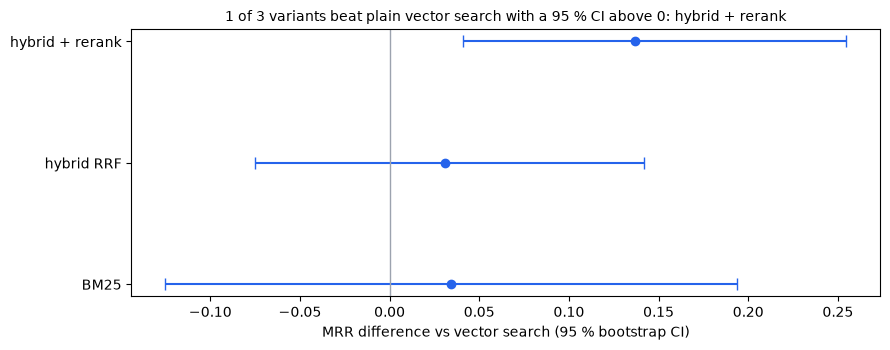

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3.6))
names = list(CI)
ds = [CI[v][0] for v in names]
err = [[CI[v][0] - CI[v][1] for v in names], [CI[v][2] - CI[v][0] for v in names]]
ax.errorbar(ds, range(len(names)), xerr=err, fmt="o", color="#2563eb", capsize=4)
ax.axvline(0, color="#9ca3af", lw=1)
ax.set_yticks(range(len(names)), names, fontsize=10)
ax.set_xlabel("MRR difference vs vector search (95 % bootstrap CI)")
real = [v for v in names if CI[v][1] > 0]
ax.set_title(f"{len(real)} of {len(names)} variants beat plain vector search with a 95 % CI above 0: "
             f"{', '.join(real) or 'none'}", fontsize=10)
plt.tight_layout(); plt.show()

Which questions moved — and which layer moved them? Rank of the first relevant chunk per question (– = not in the
top 5).

In [21]:
def first_rank(v: str, qid: str):
    keys = RUNS[qid]["ranked"][v][:K]
    q = next(g for g in GOLDEN if g[0] == qid)
    return next((i + 1 for i, k in enumerate(keys) if grade(CHUNK_BY_KEY[INDEX][k], q) == 2), "–")

moved = [{"q": qid, "question": next(g[1] for g in GOLDEN if g[0] == qid)[:60],
          **{v: first_rank(v, qid) for v in VARIANTS}}
         for qid in RUNS if len({str(first_rank(v, qid)) for v in VARIANTS}) > 1]
m.table(moved, caption=f"{len(moved)} of {len(GOLDEN)} questions rank differently across variants")

q,question,vector,BM25,hybrid RRF,hybrid + rerank
Q03,What does clause 7.3.2 say?,4,1,1,1
Q05,The claim has been waiting for documents for five weeks. Wha,–,2,4,2
Q07,Water came in from the river next to our house. Am I covered,3,4,4,2
Q08,Burglars took my diamond ring. What is the most you will pay,1,–,5,1
Q09,The soaked carpet smells. Can I throw it away before the adj,2,1,1,1
Q13,When is my house considered empty for insurance purposes?,1,3,1,1
Q16,The caller has a newborn baby and the kitchen is flooded by,–,1,–,1
Q19,My car stood in a flooded street. Is it covered and what do,4,–,3,2


> **Think about it:** At list price a rerank call costs about 700× a vector query, and its on-demand quota here is
> a few hundred times smaller. Where would you spend it only *some* of the time — and on which signal would you
> decide?

<details><summary>More questions</summary>

- Did BM25 lose a question that vector search found? If so, which word in the question explains it?
- The pool recall column caps what any reranker can do. How would you raise it without raising latency?
</details>

## 5 · What a layer costs at scale
The same per-query costs at 1 million queries a month, with the measured p50 latency. Embedding the corpus is a
one-off; queries are the bill.

In [22]:
MONTHLY = 1_000_000
m.table([{"variant": s["variant"], "MRR": s["mrr"], "p50 ms": s["p50 ms"],
          "$ / month at 1 M queries": MONTHLY * USD_PER_QUERY[s["variant"]]} for s in SCOREBOARD],
        fmt={"MRR": "{:.2f}", "p50 ms": "{:.0f}", "$ / month at 1 M queries": "${:,.0f}"})
print(f"one-off ingestion of this corpus (3 chunkers): ${ingest_usd:.4f} · "
      f"query embeddings this run: {EMBED_TOKENS['queries']} tokens")

variant,MRR,p50 ms,$ / month at 1 M queries
vector,0.80,328,$3
BM25,0.83,0,$0
hybrid RRF,0.83,329,$3
hybrid + rerank,0.93,567,"$2,003"


one-off ingestion of this corpus (3 chunkers): $0.0002 · query embeddings this run: 2491 tokens


> **Think about it:** 1 M queries a month is about 23 a minute on average — compare that with the rerank quota
> printed in §4. What do you ask for first: a quota increase, a cache, or a gate that reranks only hard questions?

## Cleanup — don't skip this
Deletes the three vector indexes, the S3 vector bucket and the documents bucket. **Run it only after Part 2** (the
console's Knowledge Base reads `s3://mlaidp2-m03-docs-<run id>/docs/`). The Knowledge Base, its vector store and its
role created in the console are deleted in the console (see DEMO_M03.md, Reset).

In [23]:
def delete_vector_bucket(name: str) -> None:
    try:
        for i in s3vectors.list_indexes(vectorBucketName=name)["indexes"]:
            s3vectors.delete_index(vectorBucketName=name, indexName=i["indexName"])
        s3vectors.delete_vector_bucket(vectorBucketName=name)
        print(f"  deleted vector bucket {name}")
    except ClientError as e:
        if m.error_code(e) != "NotFoundException":
            raise

delete_vector_bucket(VECTOR_BUCKET)
m.empty_and_delete_bucket(DOCS_BUCKET)
left = [b["vectorBucketName"] for b in s3vectors.list_vector_buckets(prefix="mlaidp2-m03-")["vectorBuckets"]
        if RID in b["vectorBucketName"]]
left += [b["Name"] for b in s3.list_buckets()["Buckets"] if b["Name"] == DOCS_BUCKET]
print("✓ nothing left" if not left else f"✗ still there: {left}")

  deleted vector bucket mlaidp2-m03-10220f2e


  deleted bucket mlaidp2-m03-docs-10220f2e


✓ nothing left
